# MAST query -- SDSS J172637.24+264127.6

Goal: test `mast_archive.query_mast`, `mast_archive.download_mast_spectra` and
`sdss_reader.read_sdss_spec` on a real target: search MAST, download the
spectrum and plot it.

MAST only holds one spectrum for this object (SDSS, plate-MJD-fiber
2182-53905-0101, no HST data). Wavelengths in Angstrom, vacuum.

In [11]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from spectral_diag.mast_archive import query_mast, download_mast_spectra
from spectral_diag.sdss_reader import read_sdss_spec

## Search

In [12]:
obs = query_mast("SDSS J172637.24+264127.6")
obs["obs_collection", "instrument_name", "obs_id", "em_min", "em_max"]

obs_collection,instrument_name,obs_id,em_min,em_max
str4,str17,str28,float64,float64
SDSS,SDSS Spectrograph,sdss_spectro_2182-53905-0101,380.0,920.0


## Download

`productSubGroupDescription="SPECTRA"` keeps the per-object files
(`spec` and `spec-lite`); `max_size_mb` skips the catalogue-wide
`specObj-dr17.fits` (~7 GB) that MAST also attaches to SDSS
observations.

In [13]:
download_dir = Path("../data/mast")
# Reuse spectra from a previous run: MAST requests have no socket timeout,
# so a hung server would block this cell indefinitely
paths = sorted(download_dir.glob("*.fits"))
if not paths:
    paths = download_mast_spectra(
        obs, download_dir=download_dir, productSubGroupDescription="SPECTRA"
    )
paths

[PosixPath('../data/mast/spec-2182-53905-0101.fits'),
 PosixPath('../data/mast/spec-lite-2182-53905-0101.fits')]

In [14]:
path = next(p for p in paths if p.name.startswith("spec-lite"))
spec = read_sdss_spec(path)
print(spec.meta)
print(f"{spec.wave.size} pixels, {spec.wave.min():.1f}-{spec.wave.max():.1f} A")
print(f"median S/N = {np.median(spec.flux / spec.error):.1f}")

{'instrument': 'SDSS', 'source': 'spec-lite-2182-53905-0101.fits', 'obs_id': '2182-53905-0101', 'ra': 261.6552, 'dec': 26.690992, 'mjd': 53905, 'exptime': 3900.4, 'wave_frame': 'vacuum, heliocentric', 'flux_unit': '1e-17 erg s^-1 cm^-2 Angstrom^-1', 'snr': 61.5799674987793, 'z': -0.00012310095189604908, 'z_err': 4.0423092286800966e-06, 'class': 'STAR', 'subclass': 'A0', 'fwhm_kms': 145.46721384510857, 'R': 2060.8936548356164}
3772 pixels, 3811.5-9206.6 A
median S/N = 61.6


## Plot

The SDSS pipeline classifies it as an A0 star at z ~ 0, so the
spectrum is dominated by pressure-broadened Balmer absorption lines.

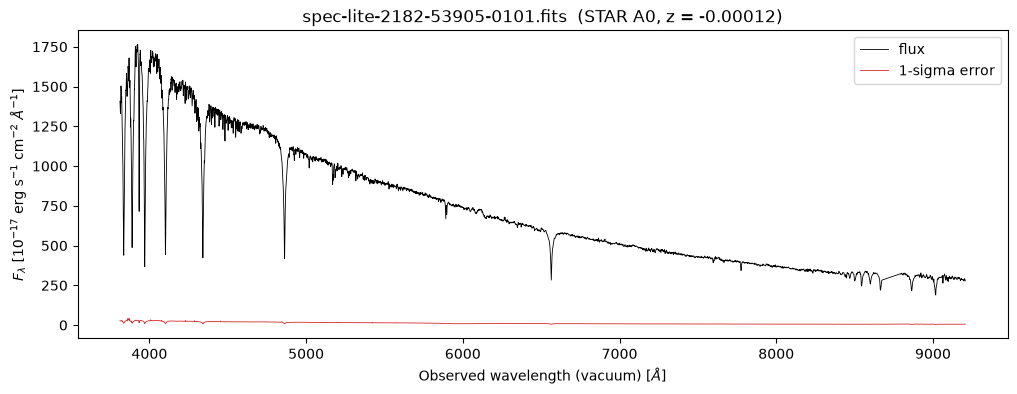

In [17]:
z = spec.meta["z"]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(spec.wave, spec.flux, lw=0.6, color="k", label="flux")
ax.plot(spec.wave, spec.error, lw=0.6, color="C3", label="1-sigma error")
ax.set_xlabel(r"Observed wavelength (vacuum) [$\AA$]")
ax.set_ylabel(r"$F_\lambda$ [$10^{-17}$ erg s$^{-1}$ cm$^{-2}$ $\AA^{-1}$]")
ax.set_title(f"{path.name}  ({spec.meta['class']} {spec.meta['subclass']}, z = {z:.5f})")
ax.legend()
plt.show()